In [1]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

import rasterio
import geopandas as gpd
import numpy as np

sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING

from torch import Tensor


In [2]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [3]:
inverse_label_mapping

{0: 'pasture',
 1: 'forest plantation',
 2: 'soy',
 3: 'coffee',
 4: 'palm oil',
 5: 'mining',
 6: 'urban',
 7: 'cocoa',
 8: 'rubber',
 9: 'forest regrowth',
 10: 'shifting agriculture'}

In [4]:
config = {
    

    "data": {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_v3/labels_forestloss_filtered.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_v3/one_image",
        "forestloss_folder": "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles",
        "output_folder":  "models_trained/"
    },

    "hyperparams" :{
        "seed": 424,
        "batch_size": 64,
        "learning_rate": [0.0005],
        "epochs": [20],
        "weight_decay": [0.002],
        "randomize_labels": ["False"],
        "model_type": "monotemporal",
        "backbone": "resnet18",
        "pretrained_backbone" : True,
        "in_channels": 4,
        "early_stopping_patience": [50],

        "use_forestloss" : True,
        "forestloss_params": 
            {
                "kernel_size" : 5,
                "sigma" : 1,
                "layer_to_apply" : 1
            }
        
    },


    "wandb": {
        "log_to_wandb" : "True",
        "project" : "project_2",
        "entity" : "janpisl",
        "group": "tmf March 2024 v2"
    }
}

In [5]:
'''
_id = 'xx7mqeiv'

model_dir = os.path.join('../models_trained', _id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())'''


    


"\n_id = 'xx7mqeiv'\n\nmodel_dir = os.path.join('../models_trained', _id)\nconfig_path = os.path.join(model_dir, 'config.json')\nwith open(config_path) as source:\n    config = json.loads(source.read())"

In [5]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [6]:
x,y = next(iter(train_dl))

In [9]:
_dir = '/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/'
path = os.path.join(_dir, os.listdir(_dir)[0])

In [10]:
with rasterio.open(path) as source:
    forestloss_data = Tensor(source.read())

In [11]:
tr = _transform_3_1(forestloss_data).permute(1, 2, 0).numpy()

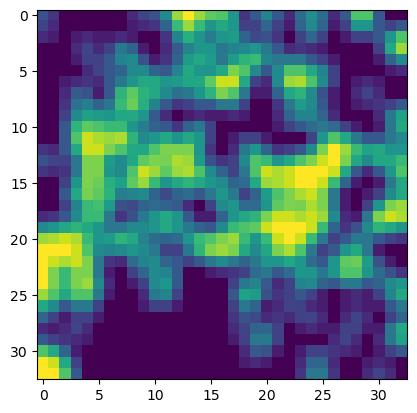

In [13]:
plt.imshow(tr.permute(1, 2, 0).numpy()  )

In [108]:
import torchvision.transforms as transforms


sigma_1 = []
for i in (3,5,7):
    sigma_1.append(
        transforms.Compose([
        transforms.GaussianBlur(
            (i,i), 
            sigma=1),
        ]) 
    )

sigma_15 = []
for i in (15,17,19):
    sigma_15.append(
        transforms.Compose([
        transforms.GaussianBlur(
            (i,i), 
            sigma=1.5),
        ]) 
    )
 



sigma_6 = []
for i in (7,13,15):
    sigma_6.append(
        transforms.Compose([
        transforms.GaussianBlur(
            (i,i), 
            sigma=6),
        
        ]) 
    )
    

    
'''
sigma_15_resize = []
for i in (3,5,7):
    sigma_15_resize.append(
        transforms.Compose([
        transforms.GaussianBlur(
            (i,i), 
            sigma=1.5),
        transforms.Resize((25, 25)),  

        ]) 
    )
    
sigma_15_resize13 = []
for i in (3,5,7):
    sigma_15_resize13.append(
        transforms.Compose([
        transforms.GaussianBlur(
            (i,i), 
            sigma=1.5),
        transforms.Resize((13, 13)),  

        ]) 
    )
'''
    

'\nsigma_15_resize = []\nfor i in (3,5,7):\n    sigma_15_resize.append(\n        transforms.Compose([\n        transforms.GaussianBlur(\n            (i,i), \n            sigma=1.5),\n        transforms.Resize((25, 25)),  \n\n        ]) \n    )\n    \nsigma_15_resize13 = []\nfor i in (3,5,7):\n    sigma_15_resize13.append(\n        transforms.Compose([\n        transforms.GaussianBlur(\n            (i,i), \n            sigma=1.5),\n        transforms.Resize((13, 13)),  \n\n        ]) \n    )\n'

In [111]:
def plot_image_with_tmf(data, tmf, label):
   
    row, cols = 3,4
    fig, ax = plt.subplots(3,3, figsize=(14, 12))
    img = data[:3, :, :].detach()
    img = img/0.25
    print(label)
    
    ax[0,0].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
    
    ax[0,0].set_xticks([])
    ax[0,0].set_yticks([])
    ax[0,1].imshow(tmf.permute(1, 2, 0).numpy()  )

    #ax[1].imshow(_transform_3_1(forestloss_data).permute(1, 2, 0).numpy()  )
    
    for i in [0,1,2]:
        #ax[1,i].imshow(sigma_15_resize[i](tmf).permute(1, 2, 0).numpy()  )
        ax[1,i].imshow(sigma_15[i](tmf).permute(1, 2, 0).numpy()  )
        ax[2,i].imshow(sigma_6[i](tmf).permute(1, 2, 0).numpy()  )

    

    fig.tight_layout()
    plt.show()


1019277
pasture


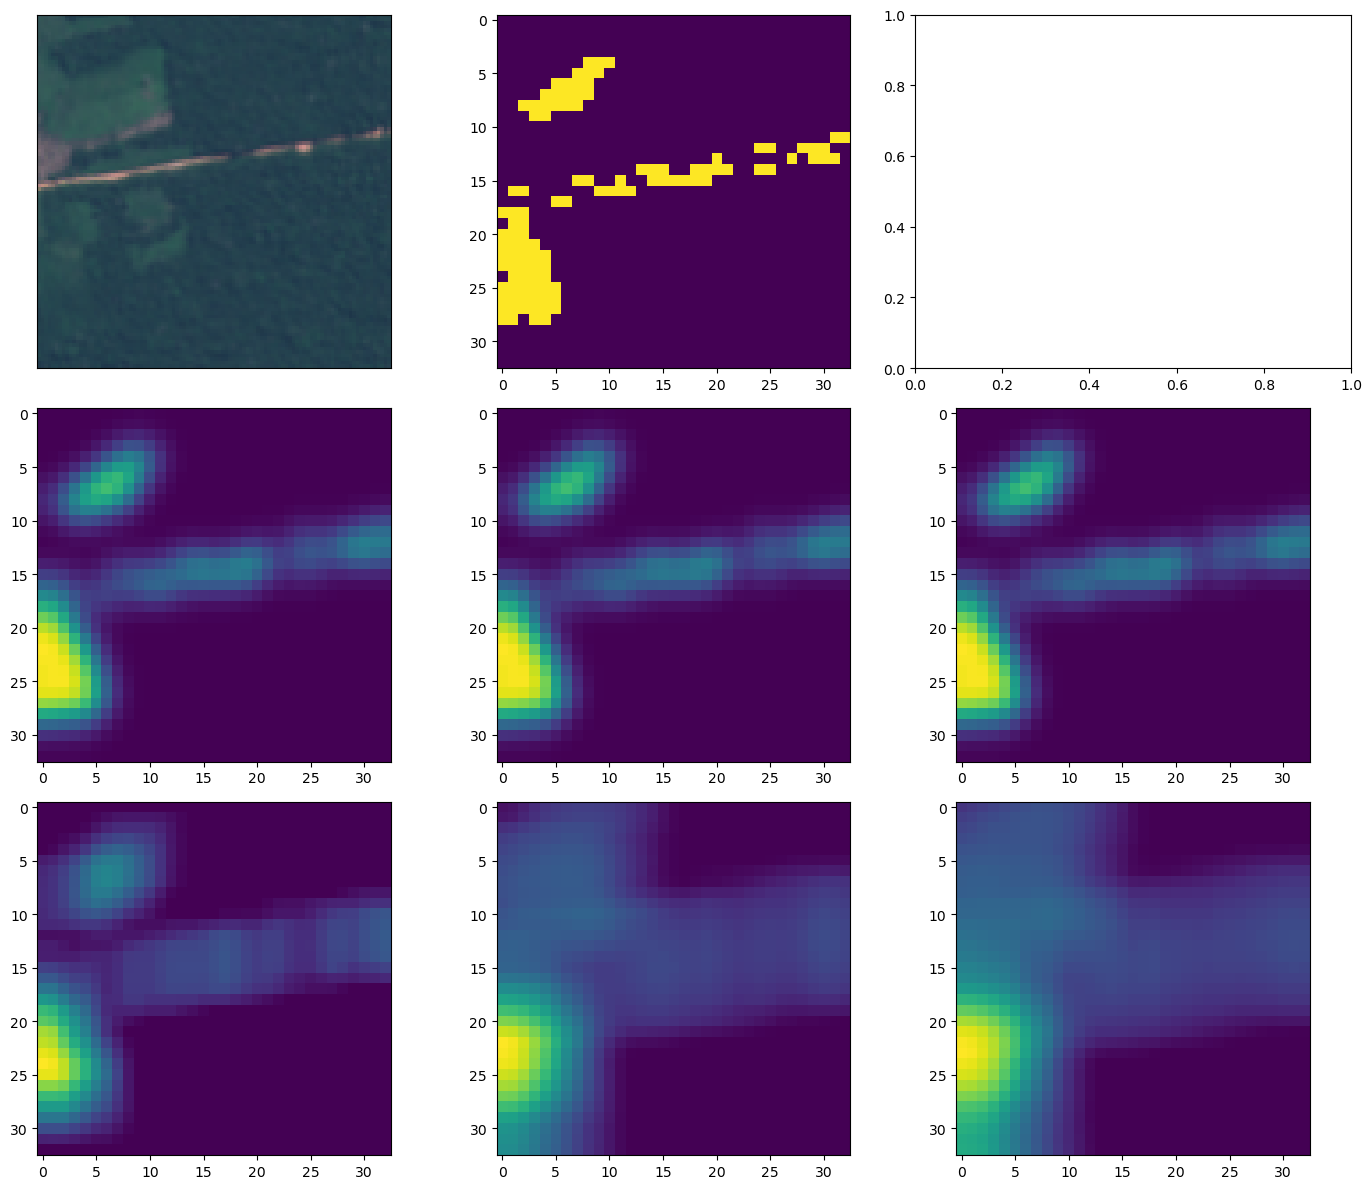

KeyboardInterrupt: Interrupted by user

In [112]:
dataset = val_dl.dataset

while True:

    i = random.randint(0,len(dataset.img_labels) - 1)
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    print(dataset.img_labels.iloc[i].sampleid)
    input_batch, label = dataset.__getitem__(i)
    x, tmf = input_batch
    #tmf = tmf.squeeze()
    if len(x.shape) == 3:
        plot_image_with_tmf(x, tmf, label=inverse_label_mapping[label])
    else:
        plot_ts_with_tmf(x, tmf, label=inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [72]:
sigma_15_resize13[0](tmf).ma()

tensor(0.)

In [ ]:
## Validation dataset

## Samples that dont seem correct
sampleids = [
    8022376, #palm oil, seems like urban
    8018941, #forest pl. looks like palm oil
    1520046, #no forest loss
    1520971, #no forest loss
    1592035, #plantation, seems like mostly pasture + some plantation
    1455371, #pasture, looks like forest
    5002846, #shifting ag., looks like palm oil
    
]


## Samples where I expect the inclusion of TMF to help 
sampleids = [
    4036370, #forest regrowth
    4027336, #regrowth
    1501571, #soy
    1531297, #soy
    1532140, #soy
    1533597, #soy
    1573773, #forest plantation
    1495331, #pasture
    4011259, # regrowth
    1059697, #pasture
    1572594, #plantation
    1591770, #soy
    8122493, #forest plant
    
]

In [35]:

### THere was a bug,  all of these are from the *TRAIN* dataset, not VAL

'''
### Here are sampleids that seem suspicious based on visualizing image + TMF
sampleids = [
    1357425, #forest plant. looks like soy
    5001347, #forest plant. looks like palm oil
    6000647,  #forest regrowth, its a road
    8062686, #no forest loss
    8144952,  #no forest loss
    2022999, #forest plant. looks like palm oil

]

## Samples where I expect the inclusion of TMF to help

sampleids = [
    1117467, #forest plantation
]

sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]'''


'\n### Here are sampleids that seem suspicious based on visualizing image + TMF\nsampleids = [\n    1357425, #forest plant. looks like soy\n    5001347, #forest plant. looks like palm oil\n    6000647,  #forest regrowth, its a road\n    8062686, #no forest loss\n    8144952,  #no forest loss\n    2022999, #forest plant. looks like palm oil\n\n]\n\n## Samples where I expect the inclusion of TMF to help\n\nsampleids = [\n    1117467, #forest plantation\n]\n\nsampleids = [\n2040330, #forest plant. looks like palm oil\n    5000927, #forest plant. looks like palm oil\n    8118421,  #forest plant. looks like palm oil\n]'